In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seaborn_plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('/content/santander_cleaned.csv')
print(f"Dataset Loaded Successfully! Shape: {df.shape}")

Dataset Loaded Successfully! Shape: (76020, 308)


In [8]:
summary_stats = df.describe().T
print("Summary Statistics (First 10 features):")
display(summary_stats.head(10))

print("\nData Types Count:")
print(df.dtypes.value_counts())

Summary Statistics (First 10 features):


,count,mean,std,min,25%,50%,75%,max
ID,76020.0,75964.050723,43781.947379,1.0,38104.75,76043.0,113748.75,151838.00
var3,76020.0,2.716483,9.447971,0.0,2.00,2.0,2.00,238.00
var15,76020.0,33.212865,12.956486,5.0,23.00,28.0,40.00,105.00
imp_ent_var16_ult1,76020.0,86.208265,1614.757313,0.0,0.00,0.0,0.00,210000.00
imp_op_var39_comer_ult1,76020.0,72.363067,339.315831,0.0,0.00,0.0,0.00,12888.03
imp_op_var39_comer_ult3,76020.0,119.529632,546.266294,0.0,0.00,0.0,0.00,21024.81
imp_op_var40_comer_ult1,76020.0,3.559130,93.155749,0.0,0.00,0.0,0.00,8237.82
imp_op_var40_comer_ult3,76020.0,6.472698,153.737066,0.0,0.00,0.0,0.00,11073.57
imp_op_var40_efect_ult1,76020.0,0.412946,30.604864,0.0,0.00,0.0,0.00,6600.00
imp_op_var40_efect_ult3,76020.0,0.567352,36.513513,0.0,0.00,0.0,0.00,6600.00



Data Types Count:
int64      197
float64    111
Name: count, dtype: int64


,Count,Percentage (%)
TARGET,,
0,73012,96.043147
1,3008,3.956853


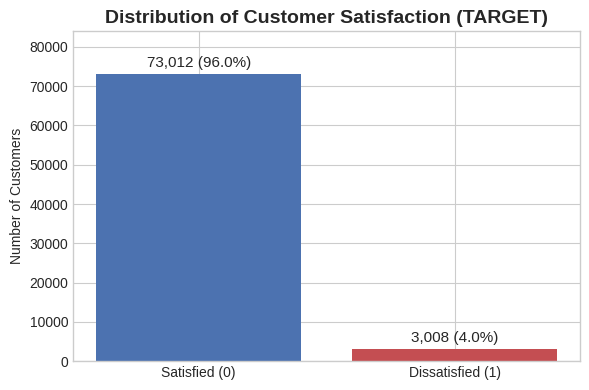

In [9]:
target_counts = df['TARGET'].value_counts()
target_percentages = df['TARGET'].value_counts(normalize=True) * 100

target_df = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_percentages
})
display(target_df)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Satisfied (0)', 'Dissatisfied (1)'], target_counts, color=['#4C72B0', '#C44E52'])
ax.set_title('Distribution of Customer Satisfaction (TARGET)', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Customers')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1000, f'{yval:,} ({yval/len(df)*100:.1f}%)',
            ha='center', va='bottom', fontsize=11)

plt.ylim(0, max(target_counts) * 1.15)
plt.tight_layout()
plt.show()

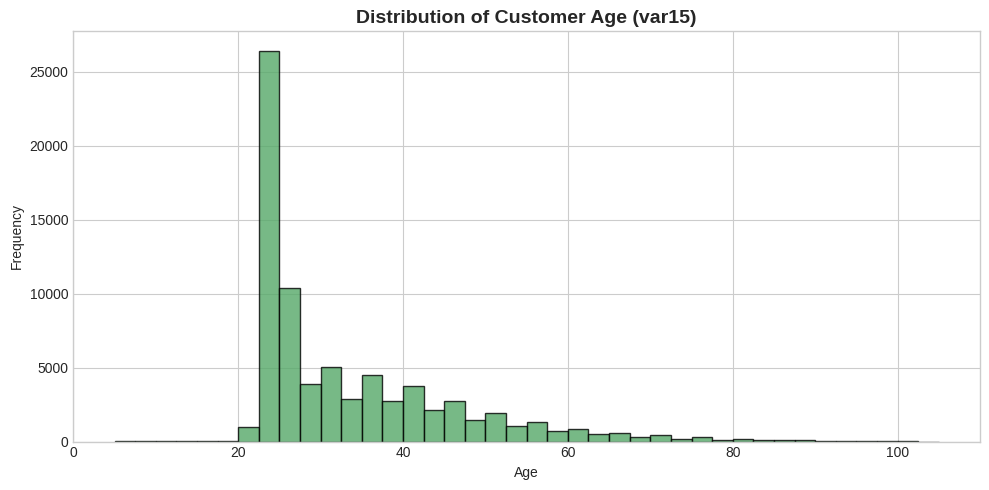

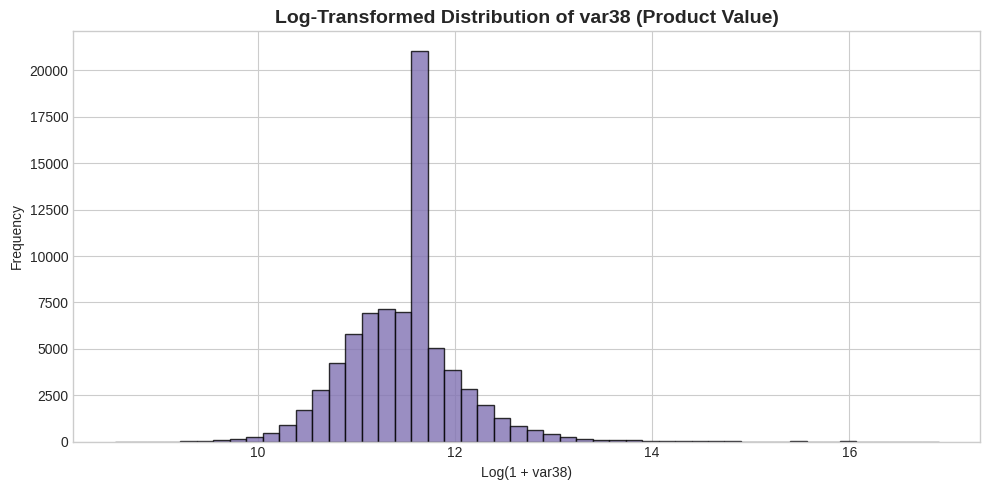

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df['var15'], bins=40, color='#55a868', edgecolor='black', alpha=0.8)
ax.set_title('Distribution of Customer Age (var15)', fontsize=14, fontweight='bold')
ax.set_xlabel('Age')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(np.log1p(df['var38']), bins=50, color='#8172b3', edgecolor='black', alpha=0.8)
ax.set_title('Log-Transformed Distribution of var38 (Product Value)', fontsize=14, fontweight='bold')
ax.set_xlabel('Log(1 + var38)')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

Top 10 Features Positively Correlated with Dissatisfaction (TARGET = 1):
TARGET                     1.000000
var36                      0.102919
var15                      0.101322
ind_var8_0                 0.046665
num_var8_0                 0.046622
imp_op_var39_efect_ult1    0.030380
imp_op_var41_efect_ult1    0.029479
num_var8                   0.027926
ind_var8                   0.027926
imp_op_var41_ult1          0.027586
imp_op_var39_ult1          0.027416
Name: TARGET, dtype: float64

Top 10 Features Negatively Correlated with Dissatisfaction:
ind_var13_0           -0.039471
ind_var13             -0.039612
num_var35             -0.076872
num_var4              -0.080194
num_var5              -0.134095
ind_var5              -0.135349
num_var42             -0.135693
num_var30             -0.138289
num_meses_var5_ult3   -0.148253
ind_var30             -0.149811
Name: TARGET, dtype: float64


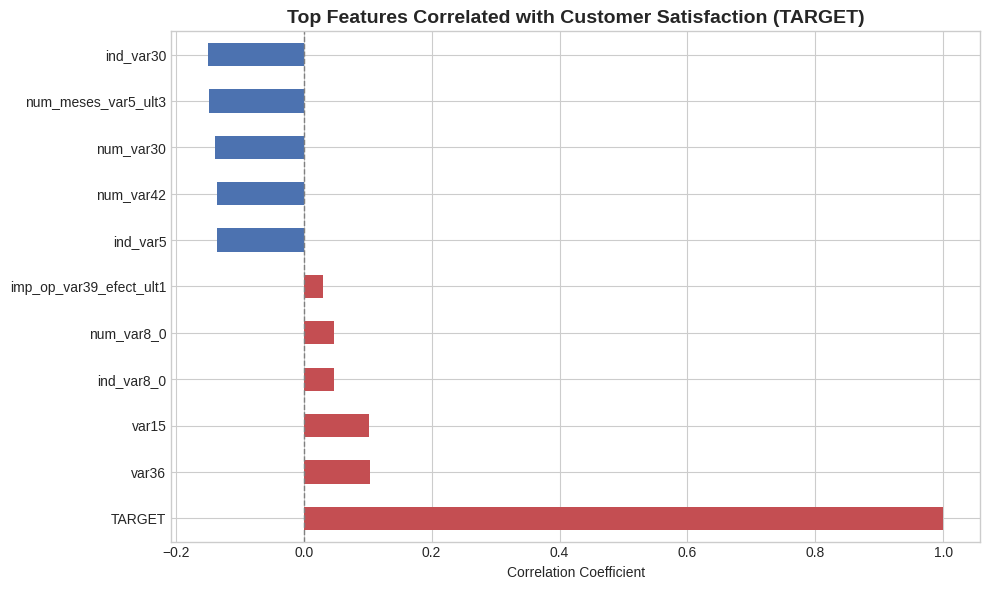

In [11]:
correlations = df.corr()['TARGET'].sort_values(ascending=False)

print("Top 10 Features Positively Correlated with Dissatisfaction (TARGET = 1):")
print(correlations.head(11))

print("\nTop 10 Features Negatively Correlated with Dissatisfaction:")
print(correlations.tail(10))

top_features = pd.concat([correlations.head(6), correlations.tail(5)])
fig, ax = plt.subplots(figsize=(10, 6))
top_features.plot(kind='barh', color=['#C44E52' if x > 0 else '#4C72B0' for x in top_features], ax=ax)
ax.set_title('Top Features Correlated with Customer Satisfaction (TARGET)', fontsize=14, fontweight='bold')
ax.set_xlabel('Correlation Coefficient')
plt.axvline(x=0, color='grey', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()